<a href="https://colab.research.google.com/github/Ag3-S/Neural-Networks-Lab/blob/main/Ag_Practice_6_Pytorch_completeModel_HyperparamStudy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Pytorch:1

### Working with data
PyTorch has two primitives to work with data: torch.utils.data.DataLoader and torch.utils.data.Dataset. Dataset stores the samples and their corresponding labels, and DataLoader wraps an iterable around the Dataset.

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt

PyTorch offers domain-specific libraries such as TorchText, TorchVision, and TorchAudio, all of which include datasets. For this notebook, we will be using a TorchVision dataset.

The torchvision.datasets module contains Dataset objects for many real-world vision data like CIFAR, COCO (full list here). In this tutorial, we use the FashionMNIST dataset. Every TorchVision Dataset includes two arguments: transform and target_transform to modify the samples and labels respectively.

In [2]:
# Download training data from open datasets.
training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.81MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.6MB/s]


We pass the Dataset as an argument to DataLoader. This wraps an iterable over our dataset, and supports automatic batching, sampling, shuffling and multiprocess data loading. Here we define a batch size of 64, i.e. each element in the dataloader iterable will return a batch of 64 features and labels.

In [3]:
batch_size = 64

# Create data loaders.
train_dataloader = DataLoader(training_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

for X, y in train_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


In [4]:
print(training_data.data.shape)
print(test_data.data.shape)

torch.Size([60000, 28, 28])
torch.Size([10000, 28, 28])


## Iterating and Visualizing the Dataset

We can index ``Datasets`` manually like a list: ``training_data[index]``.
We use ``matplotlib`` to visualize some samples in our training data.



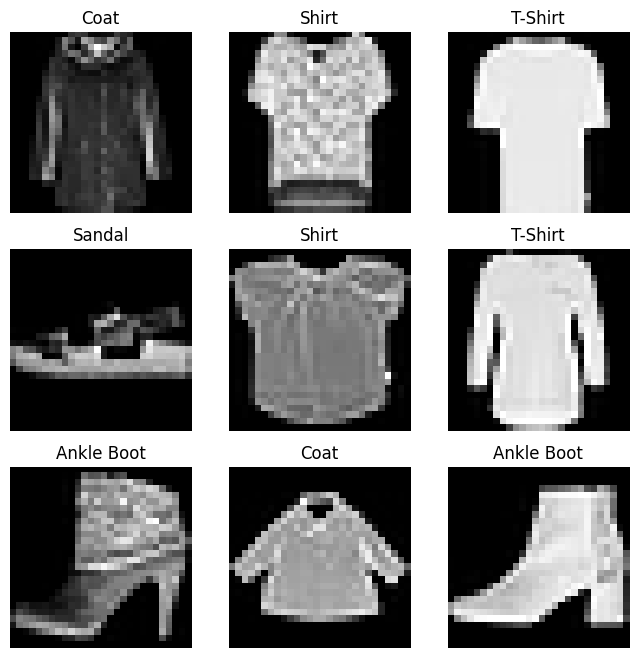

In [5]:

labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

### Creating Models
To define a neural network in PyTorch, we create a class that inherits from nn.Module. We define the layers of the network in the __init__ function and specify how data will pass through the network in the forward function. To accelerate operations in the neural network, we move it to the GPU or MPS if available.

In [6]:
# Get cpu, gpu or mps device for training.
device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device")

# Define model
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

Using cuda device
NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


### Optimizing the Model Parameters
To train a model, we need a loss function and an optimizer.

In [7]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

In a single training loop, the model makes predictions on the training dataset (fed to it in batches), and backpropagates the prediction error to adjust the model’s parameters.

In [8]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

We also check the model’s performance against the test dataset to ensure it is learning.

In [9]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

The training process is conducted over several iterations (epochs). During each epoch, the model learns parameters to make better predictions. We print the model’s accuracy and loss at each epoch; we’d like to see the accuracy increase and the loss decrease with every epoch.

In [10]:
epochs = 5
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 2.312420  [   64/60000]
loss: 2.298858  [ 6464/60000]
loss: 2.276228  [12864/60000]
loss: 2.263723  [19264/60000]
loss: 2.252535  [25664/60000]
loss: 2.221133  [32064/60000]
loss: 2.235569  [38464/60000]
loss: 2.204200  [44864/60000]
loss: 2.207515  [51264/60000]
loss: 2.164660  [57664/60000]
Test Error: 
 Accuracy: 43.4%, Avg loss: 2.163562 

Epoch 2
-------------------------------
loss: 2.180950  [   64/60000]
loss: 2.165496  [ 6464/60000]
loss: 2.108477  [12864/60000]
loss: 2.119111  [19264/60000]
loss: 2.067506  [25664/60000]
loss: 2.010439  [32064/60000]
loss: 2.042750  [38464/60000]
loss: 1.966056  [44864/60000]
loss: 1.981181  [51264/60000]
loss: 1.888903  [57664/60000]
Test Error: 
 Accuracy: 52.6%, Avg loss: 1.895819 

Epoch 3
-------------------------------
loss: 1.934781  [   64/60000]
loss: 1.896626  [ 6464/60000]
loss: 1.783298  [12864/60000]
loss: 1.820553  [19264/60000]
loss: 1.704971  [25664/60000]
loss: 1.655421  [32064/600

### Saving Models
A common way to save a model is to serialize the internal state dictionary (containing the model parameters).

In [11]:
torch.save(model.state_dict(), "model.pth")
print("Saved PyTorch Model State to model.pth")

Saved PyTorch Model State to model.pth


### Loading Models
The process for loading a model includes re-creating the model structure and loading the state dictionary into it.

In [12]:
model = NeuralNetwork().to(device)
model.load_state_dict(torch.load("model.pth"))

<All keys matched successfully>

This model can now be used to make predictions.

In [13]:
classes = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

model.eval()
x, y = test_data[10][0], test_data[10][1]
with torch.no_grad():
    x = x.to(device)
    pred = model(x)
    predicted, actual = classes[pred[0].argmax(0)], classes[y]
    print(f'Predicted: "{predicted}", Actual: "{actual}"')

Predicted: "Coat", Actual: "Coat"


---
# Part 2: Hyper-parameter Comparison Study

Everything above is the original notebook (baseline: **2 hidden layers, ReLU, SGD, 5 epochs, no normalization/dropout**).
From here on we change the five things you asked for and collect the results into an Excel sheet on Google Drive:

| # | What changes | Options compared |
|---|---|---|
| 1 | **Number of hidden layers** | 1, 2, 3, 4 |
| 2 | **Activation function** | ReLU, LeakyReLU, Tanh, GELU, Sigmoid |
| 3 | **Epochs** | 5, 10, 20 (recorded as checkpoints of one 20-epoch run) |
| 4 | **Optimizer** | SGD, SGD+Momentum, Adam, RMSprop |
| 5 | **Normalization / Dropout** | NoReg (none), BatchNorm, Dropout(0.3), BatchNorm+Dropout |

**How to use:** use a **GPU runtime** (Runtime → Change runtime type → T4 GPU), then run all cells from the top (the cells below reuse `device`, `training_data` and `test_data` from Part 1). Results are saved to Drive after every run, so if Colab disconnects you can just re-run the notebook and it resumes where it stopped.

### Step 1: Mount Google Drive

In [15]:
# ---- Mount Google Drive (results will be saved here) ----
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUTPUT_DIR = '/content/drive/MyDrive/PyTorch_HyperParam_Experiments'
except ImportError:
    # Not running in Colab -> save next to the notebook instead
    OUTPUT_DIR = './PyTorch_HyperParam_Experiments'

os.makedirs(OUTPUT_DIR, exist_ok=True)
HISTORY_CSV = os.path.join(OUTPUT_DIR, 'experiment_history.csv')   # raw per-epoch log (also used to resume)
EXCEL_PATH  = os.path.join(OUTPUT_DIR, 'hyperparameter_comparison.xlsx')
print('Results folder :', OUTPUT_DIR)
print('Excel file     :', EXCEL_PATH)

Mounted at /content/drive
Results folder : /content/drive/MyDrive/PyTorch_HyperParam_Experiments
Excel file     : /content/drive/MyDrive/PyTorch_HyperParam_Experiments/hyperparameter_comparison.xlsx


### Step 2: Choose what to compare
Edit the lists below to add or remove options. `SEARCH_MODE` controls how many combinations are run.

In [16]:
# =====================================================================
#  EXPERIMENT SETTINGS  -  edit this cell to change what gets compared
# =====================================================================
import itertools, random, time
import numpy as np
import pandas as pd

SEED        = 42
BATCH_SIZE  = 64          # same as the original notebook
HIDDEN_WIDTH = 512        # neurons per hidden layer (same as original)
DROPOUT_P   = 0.3         # drop probability used by the "Dropout" options

# 3) Epochs: every run is trained up to the largest value and the test accuracy
#    is recorded at each of these checkpoints (so epochs come "for free").
EPOCH_CHECKPOINTS = [5, 10, 20]
MAX_EPOCHS = max(EPOCH_CHECKPOINTS)

# 1) Number of hidden layers
HIDDEN_LAYERS_OPTIONS = [1, 2, 3, 4]

# 2) Activation functions
ACTIVATION_OPTIONS = ["ReLU", "LeakyReLU", "Tanh", "GELU", "Sigmoid"]

# 4) Optimizers  (name -> constructor). Edit learning rates here if you like.
OPTIMIZER_SETTINGS = {
    "SGD":          lambda p: torch.optim.SGD(p, lr=1e-3),                 # original notebook
    "SGD+Momentum": lambda p: torch.optim.SGD(p, lr=1e-3, momentum=0.9),
    "Adam":         lambda p: torch.optim.Adam(p, lr=1e-3),
    "RMSprop":      lambda p: torch.optim.RMSprop(p, lr=1e-3),
}
OPTIMIZER_OPTIONS = list(OPTIMIZER_SETTINGS.keys())

# 5) Normalization / Dropout
REGULARIZATION_OPTIONS = ["NoReg", "BatchNorm", "Dropout", "BatchNorm+Dropout"]

# The reference run = exactly what the original notebook trains
BASELINE = dict(hidden_layers=2, activation="ReLU", optimizer="SGD", regularization="NoReg")

# How to pick the combinations to run (the baseline + one-factor-at-a-time runs are ALWAYS included):
#   "random" -> N_RANDOM_COMBOS random combinations from the full grid  (fast, good overview)
#   "grid"   -> every combination of all options above                  (4*5*4*4 = 320 runs, takes hours)
SEARCH_MODE     = "random"
N_RANDOM_COMBOS = 40

print(f"Full grid size: {len(HIDDEN_LAYERS_OPTIONS)*len(ACTIVATION_OPTIONS)*len(OPTIMIZER_OPTIONS)*len(REGULARIZATION_OPTIONS)} combinations "
      f"(x {len(EPOCH_CHECKPOINTS)} epoch checkpoints, recorded for free)")

Full grid size: 320 combinations (x 3 epoch checkpoints, recorded for free)


### Step 3: Configurable model, optimizers and fast data handling

In [17]:
# ---- Flexible model + helpers ----
ACTIVATIONS = {
    "ReLU":      lambda: nn.ReLU(),
    "LeakyReLU": lambda: nn.LeakyReLU(0.01),
    "Tanh":      lambda: nn.Tanh(),
    "GELU":      lambda: nn.GELU(),
    "Sigmoid":   lambda: nn.Sigmoid(),
}

class FlexibleNet(nn.Module):
    """Same MLP as before, but depth / activation / normalization / dropout are configurable."""
    def __init__(self, hidden_layers, activation, regularization, width=HIDDEN_WIDTH, dropout_p=DROPOUT_P):
        super().__init__()
        use_bn = "BatchNorm" in regularization
        use_do = "Dropout" in regularization
        layers = [nn.Flatten()]
        in_features = 28 * 28
        for _ in range(hidden_layers):
            layers.append(nn.Linear(in_features, width))
            if use_bn:
                layers.append(nn.BatchNorm1d(width))      # normalise before the activation
            layers.append(ACTIVATIONS[activation]())
            if use_do:
                layers.append(nn.Dropout(dropout_p))
            in_features = width
        layers.append(nn.Linear(in_features, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def config_id(c):
    return f"L{c['hidden_layers']}|{c['activation']}|{c['optimizer']}|{c['regularization']}"

# ---- Keep the whole dataset on the device -> much faster than a DataLoader for many runs ----
def to_device_tensors(ds):
    X = ds.data.float().div(255.0).unsqueeze(1)   # identical to ToTensor(): [N,1,28,28] in [0,1]
    y = ds.targets.long()
    return X.to(device), y.to(device)

X_train, y_train = to_device_tensors(training_data)
X_test,  y_test  = to_device_tensors(test_data)
print("Train:", tuple(X_train.shape), " Test:", tuple(X_test.shape), " device:", device)

@torch.no_grad()
def evaluate(model, X, y, chunk=5000):
    model.eval()
    total_loss, correct = 0.0, 0
    for i in range(0, len(X), chunk):
        out = model(X[i:i+chunk])
        total_loss += nn.functional.cross_entropy(out, y[i:i+chunk], reduction="sum").item()
        correct    += (out.argmax(1) == y[i:i+chunk]).sum().item()
    return total_loss / len(X), 100.0 * correct / len(X)

Train: (60000, 1, 28, 28)  Test: (10000, 1, 28, 28)  device: cuda


### Step 4: Train and evaluate one configuration

In [18]:
# ---- Train ONE configuration for MAX_EPOCHS and log every epoch ----
def run_experiment(cfg):
    torch.manual_seed(SEED)
    if device == "cuda":
        torch.cuda.manual_seed_all(SEED)
    shuffle_gen = torch.Generator().manual_seed(SEED)

    model = FlexibleNet(cfg["hidden_layers"], cfg["activation"], cfg["regularization"]).to(device)
    optimizer = OPTIMIZER_SETTINGS[cfg["optimizer"]](model.parameters())
    loss_fn = nn.CrossEntropyLoss()
    n_params = sum(p.numel() for p in model.parameters())
    n_train = len(X_train)

    rows, t0 = [], time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        perm = torch.randperm(n_train, generator=shuffle_gen).to(device)
        for i in range(0, n_train, BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            loss = loss_fn(model(X_train[idx]), y_train[idx])
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

        # metrics measured in eval mode (dropout off, BatchNorm uses running stats)
        tr_loss, tr_acc = evaluate(model, X_train, y_train)
        te_loss, te_acc = evaluate(model, X_test,  y_test)
        rows.append(dict(
            config_id=config_id(cfg), hidden_layers=cfg["hidden_layers"], activation=cfg["activation"],
            optimizer=cfg["optimizer"], regularization=cfg["regularization"], epoch=epoch,
            train_loss=tr_loss, train_acc=tr_acc, test_loss=te_loss, test_acc=te_acc,
            params=n_params, elapsed_s=time.time() - t0))
    return rows

### Step 5: Build the list of experiments
The plan always contains the baseline, plus every single change from the baseline (one hyper-parameter at a time), plus combinations of all five factors.

In [19]:
# ---- Decide which combinations to run ----
def variant(**changes):
    c = dict(BASELINE); c.update(changes); return c

# baseline + change ONE hyper-parameter at a time (cleanest view of each effect)
ofat = [dict(BASELINE)]
ofat += [variant(hidden_layers=v) for v in HIDDEN_LAYERS_OPTIONS if v != BASELINE["hidden_layers"]]
ofat += [variant(activation=v)    for v in ACTIVATION_OPTIONS    if v != BASELINE["activation"]]
ofat += [variant(optimizer=v)     for v in OPTIMIZER_OPTIONS     if v != BASELINE["optimizer"]]
ofat += [variant(regularization=v) for v in REGULARIZATION_OPTIONS if v != BASELINE["regularization"]]

full_grid = [dict(hidden_layers=h, activation=a, optimizer=o, regularization=r)
             for h, a, o, r in itertools.product(HIDDEN_LAYERS_OPTIONS, ACTIVATION_OPTIONS,
                                                 OPTIMIZER_OPTIONS, REGULARIZATION_OPTIONS)]

ofat_ids = {config_id(c) for c in ofat}
if SEARCH_MODE == "grid":
    extra = [c for c in full_grid if config_id(c) not in ofat_ids]
else:
    pool = [c for c in full_grid if config_id(c) not in ofat_ids]
    extra = random.Random(SEED).sample(pool, min(N_RANDOM_COMBOS, len(pool)))

experiments = ofat + extra
print(f"{len(ofat)} one-factor-at-a-time runs + {len(extra)} combination runs = {len(experiments)} runs "
      f"x {MAX_EPOCHS} epochs each")

14 one-factor-at-a-time runs + 40 combination runs = 54 runs x 20 epochs each


### Step 6: Run all experiments
This is the slow cell. Progress and ETA are printed after every run.

In [20]:
# ---- Run everything (safe to re-run: finished configs are skipped, progress is saved to Drive) ----
if os.path.exists(HISTORY_CSV):
    history = pd.read_csv(HISTORY_CSV)
    done = set(history.groupby("config_id")["epoch"].max().loc[lambda s: s >= MAX_EPOCHS].index)
    history = history[history["config_id"].isin(done)]
    print(f"Resuming: {len(done)} configurations already finished, skipping them.")
else:
    history, done = pd.DataFrame(), set()

todo = [c for c in experiments if config_id(c) not in done]
start = time.time()
for n, cfg in enumerate(todo, 1):
    rows = run_experiment(cfg)
    history = pd.concat([history, pd.DataFrame(rows)], ignore_index=True)
    history.to_csv(HISTORY_CSV, index=False)                    # checkpoint after every run
    last = rows[-1]
    elapsed = time.time() - start
    eta = elapsed / n * (len(todo) - n)
    print(f"[{n:>3}/{len(todo)}] {config_id(cfg):<42} test acc @ {MAX_EPOCHS} ep: {last['test_acc']:.2f}%   "
          f"(elapsed {elapsed/60:.1f} min, ETA {eta/60:.1f} min)")
print("\nAll runs finished.")

[  1/54] L2|ReLU|SGD|NoReg                          test acc @ 20 ep: 78.15%   (elapsed 0.4 min, ETA 21.2 min)
[  2/54] L1|ReLU|SGD|NoReg                          test acc @ 20 ep: 79.38%   (elapsed 0.7 min, ETA 19.0 min)
[  3/54] L3|ReLU|SGD|NoReg                          test acc @ 20 ep: 75.83%   (elapsed 1.2 min, ETA 20.3 min)
[  4/54] L4|ReLU|SGD|NoReg                          test acc @ 20 ep: 69.97%   (elapsed 1.7 min, ETA 21.4 min)
[  5/54] L2|LeakyReLU|SGD|NoReg                     test acc @ 20 ep: 78.16%   (elapsed 2.1 min, ETA 20.6 min)
[  6/54] L2|Tanh|SGD|NoReg                          test acc @ 20 ep: 79.21%   (elapsed 2.5 min, ETA 20.0 min)
[  7/54] L2|GELU|SGD|NoReg                          test acc @ 20 ep: 76.84%   (elapsed 2.9 min, ETA 19.4 min)
[  8/54] L2|Sigmoid|SGD|NoReg                       test acc @ 20 ep: 50.32%   (elapsed 3.3 min, ETA 18.9 min)
[  9/54] L2|ReLU|SGD+Momentum|NoReg                 test acc @ 20 ep: 86.12%   (elapsed 3.7 min, ETA 18.5 min)
[

### Step 7: Create the Excel comparison table
Saved on your Drive with 5 sheets: `Summary_All_Runs`, `One_Factor_At_A_Time`, `Avg_Effect_Per_Value`, `Epoch_History`, `Settings`.

In [21]:
# ---- Build the comparison Excel workbook ----
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.formatting.rule import ColorScaleRule
from openpyxl.utils import get_column_letter

hist    = history.copy()
base_id = config_id(BASELINE)
FACTORS = [("hidden_layers", "Hidden Layers"), ("activation", "Activation"),
           ("optimizer", "Optimizer"), ("regularization", "Regularization")]

def study_label(cid):
    if cid == base_id:  return "Baseline"
    return "One factor changed" if cid in ofat_ids else "Combination"

# ---------- one row per configuration ----------
recs = []
for cid, g in hist.groupby("config_id", sort=False):
    g = g.sort_values("epoch").set_index("epoch")
    fin, best_ep = g.loc[MAX_EPOCHS], g["test_acc"].idxmax()
    r = {"Study": study_label(cid),
         "Hidden Layers": int(fin["hidden_layers"]), "Activation": fin["activation"],
         "Optimizer": fin["optimizer"], "Regularization": fin["regularization"],
         "Parameters": int(fin["params"])}
    for e in EPOCH_CHECKPOINTS:
        r[f"Test Acc % @ {e} ep"] = g.loc[e, "test_acc"]
    r[f"Test Loss @ {MAX_EPOCHS} ep"]  = fin["test_loss"]
    r[f"Train Acc % @ {MAX_EPOCHS} ep"] = fin["train_acc"]
    r["Overfit Gap (Train-Test Acc, pts)"] = fin["train_acc"] - fin["test_acc"]
    r["Best Test Acc %"] = g.loc[best_ep, "test_acc"]
    r["Best Epoch"] = int(best_ep)
    r["Train Time (s)"] = fin["elapsed_s"]
    recs.append(r)

summary = pd.DataFrame(recs)
FINAL = f"Test Acc % @ {MAX_EPOCHS} ep"
base_final = summary.loc[summary["Study"] == "Baseline", FINAL].iloc[0]
summary["Change vs Baseline (pts)"] = summary[FINAL] - base_final
summary = summary.sort_values(FINAL, ascending=False).reset_index(drop=True)
summary.insert(0, "Rank", summary.index + 1)

# ---------- one-factor-at-a-time sheet ----------
acc_cols = [f"Test Acc % @ {e} ep" for e in EPOCH_CHECKPOINTS]
base_row = summary[summary["Study"] == "Baseline"].iloc[0]
oq = []
for _, r in summary[summary["Study"] != "Combination"].iterrows():
    changed = [(lab, r[lab]) for _, lab in FACTORS
               if r[lab] != base_row[lab]]
    factor, value = changed[0] if changed else ("(baseline)", "-")
    row = {"Hyperparameter Changed": factor, "Value": value}
    for c in acc_cols:
        row[c] = r[c]
    for c in acc_cols:
        row["Change @ " + c.split("@ ")[1] + " (pts)"] = r[c] - base_row[c]
    row[f"Test Loss @ {MAX_EPOCHS} ep"] = r[f"Test Loss @ {MAX_EPOCHS} ep"]
    row["Overfit Gap (Train-Test Acc, pts)"] = r["Overfit Gap (Train-Test Acc, pts)"]
    oq.append(row)
order = {"(baseline)": 0, "Hidden Layers": 1, "Activation": 2, "Optimizer": 3, "Regularization": 4}
one_factor = pd.DataFrame(oq)
one_factor["_o"] = one_factor["Hyperparameter Changed"].map(order)
one_factor = one_factor.sort_values(["_o", "Value"], kind="stable").drop(columns="_o").reset_index(drop=True)

# ---------- average effect of each hyper-parameter value (over ALL runs that used it) ----------
av = []
for col, lab in FACTORS:
    for val, g in summary.groupby(lab):
        row = {"Hyperparameter": lab, "Value": val, "Runs": len(g)}
        for c in acc_cols:
            row["Mean " + c] = g[c].mean()
        row[f"Best {FINAL}"] = g[FINAL].max()
        row["Mean Overfit Gap (pts)"] = g["Overfit Gap (Train-Test Acc, pts)"].mean()
        row["Mean Train Time (s)"] = g["Train Time (s)"].mean()
        av.append(row)
avg_df = pd.DataFrame(av)

# ---------- raw per-epoch history ----------
epoch_hist = hist.rename(columns={
    "config_id": "Run", "hidden_layers": "Hidden Layers", "activation": "Activation",
    "optimizer": "Optimizer", "regularization": "Regularization", "epoch": "Epoch",
    "train_loss": "Train Loss", "train_acc": "Train Acc %", "test_loss": "Test Loss",
    "test_acc": "Test Acc %", "params": "Parameters", "elapsed_s": "Elapsed (s)"})

settings = pd.DataFrame({"Setting": [
    "Dataset", "Batch size", "Hidden width", "Dropout p", "Random seed", "Epoch checkpoints", "Search mode",
    "Optimizers", "Hidden layers tried", "Activations tried", "Regularization tried", "Device", "Notes"],
 "Value": [
    "FashionMNIST (60k train / 10k test)", BATCH_SIZE, HIDDEN_WIDTH, DROPOUT_P, SEED,
    str(EPOCH_CHECKPOINTS), f"{SEARCH_MODE} ({len(summary)} runs)",
    "SGD lr=1e-3 | SGD+Momentum lr=1e-3 m=0.9 | Adam lr=1e-3 | RMSprop lr=1e-3",
    str(HIDDEN_LAYERS_OPTIONS), ", ".join(ACTIVATION_OPTIONS), ", ".join(REGULARIZATION_OPTIONS), device,
    "Accuracy is TEST accuracy in %. Each run is trained once up to the max epoch; the @5/@10/@20 columns "
    "are snapshots of that same run. Train metrics are measured in eval mode. 'Baseline' = original notebook "
    "(2 hidden layers, ReLU, SGD, no norm/dropout). Averages sheet mixes all runs, so in 'random' mode it is only "
    "approximately balanced; use SEARCH_MODE='grid' for a perfectly balanced comparison. One seed per config -> "
    "differences below ~0.3-0.5 pts may just be noise."]})

# ---------- write + style ----------
HEAD_FILL = PatternFill("solid", start_color="1F4E78")
BASE_FILL = PatternFill("solid", start_color="FFF2CC")

def style_sheet(ws, df, highlight_baseline=False):
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions
    ws.row_dimensions[1].height = 45
    for j, name in enumerate(df.columns, 1):
        cell = ws.cell(row=1, column=j)
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = HEAD_FILL
        cell.alignment = Alignment(wrap_text=True, horizontal="center", vertical="center")
        width = max([len(str(name)) * 0.6] + [len(str(v)) for v in df.iloc[:, j-1].head(200)]) + 3
        ws.column_dimensions[get_column_letter(j)].width = min(max(width, 11), 60)
        letter, n = get_column_letter(j), len(df) + 1
        is_num = pd.api.types.is_float_dtype(df.iloc[:, j-1])
        if is_num:
            for r in range(2, n + 1):
                ws.cell(row=r, column=j).number_format = "0.00"
        if len(df) > 1 and ("Acc %" in name or "Test Acc" in name) and "Gap" not in name:
            ws.conditional_formatting.add(f"{letter}2:{letter}{n}", ColorScaleRule(
                start_type="min", start_color="F8696B", mid_type="percentile", mid_value=50,
                mid_color="FFEB84", end_type="max", end_color="63BE7B"))
        if len(df) > 1 and (name.startswith("Change") or "Change @" in name):
            ws.conditional_formatting.add(f"{letter}2:{letter}{n}", ColorScaleRule(
                start_type="min", start_color="F8696B", mid_type="num", mid_value=0,
                mid_color="FFFFFF", end_type="max", end_color="63BE7B"))
        if len(df) > 1 and "Overfit Gap" in name:
            ws.conditional_formatting.add(f"{letter}2:{letter}{n}", ColorScaleRule(
                start_type="min", start_color="63BE7B", mid_type="percentile", mid_value=50,
                mid_color="FFEB84", end_type="max", end_color="F8696B"))
    if highlight_baseline and "Study" in df.columns:
        for i, s in enumerate(df["Study"], 2):
            if s == "Baseline":
                for j in range(1, len(df.columns) + 1):
                    ws.cell(row=i, column=j).fill = BASE_FILL

with pd.ExcelWriter(EXCEL_PATH, engine="openpyxl") as writer:
    sheets = [("Summary_All_Runs", summary), ("One_Factor_At_A_Time", one_factor),
              ("Avg_Effect_Per_Value", avg_df), ("Epoch_History", epoch_hist), ("Settings", settings)]
    for name, df in sheets:
        df.to_excel(writer, sheet_name=name, index=False)
    for name, df in sheets:
        ws = writer.sheets[name]
        if name == "Settings":
            ws.column_dimensions["A"].width = 22; ws.column_dimensions["B"].width = 110
            for row in ws.iter_rows(min_row=2):
                row[1].alignment = Alignment(wrap_text=True, vertical="top")
            for c in ws[1]:
                c.font = Font(bold=True, color="FFFFFF"); c.fill = HEAD_FILL
        else:
            style_sheet(ws, df, highlight_baseline=(name == "Summary_All_Runs"))

print(f"Excel saved -> {EXCEL_PATH}")
print("Sheets:", [n for n, _ in sheets])
display(summary.head(10))

Excel saved -> /content/drive/MyDrive/PyTorch_HyperParam_Experiments/hyperparameter_comparison.xlsx
Sheets: ['Summary_All_Runs', 'One_Factor_At_A_Time', 'Avg_Effect_Per_Value', 'Epoch_History', 'Settings']


,Rank,Study,Hidden Layers,Activation,Optimizer,Regularization,Parameters,Test Acc % @ 5 ep,Test Acc % @ 10 ep,Test Acc % @ 20 ep,Test Loss @ 20 ep,Train Acc % @ 20 ep,"Overfit Gap (Train-Test Acc, pts)",Best Test Acc %,Best Epoch,Train Time (s),Change vs Baseline (pts)
0,1,One factor changed,2,ReLU,Adam,NoReg,669706,88.22,88.32,89.98,0.379369,95.465000,5.485000,89.98,20,28.111887,11.83
1,2,Combination,3,LeakyReLU,Adam,BatchNorm+Dropout,935434,87.93,88.53,89.98,0.294038,94.886667,4.906667,89.98,20,46.949111,11.83
2,3,Combination,4,ReLU,Adam,BatchNorm,1199114,87.65,88.04,89.89,0.377355,97.043333,7.153333,89.89,20,51.551332,11.74
3,4,Combination,2,Sigmoid,Adam,Dropout,669706,87.18,87.96,89.73,0.301029,93.030000,3.300000,89.73,20,30.705703,11.58
4,5,Combination,3,LeakyReLU,Adam,BatchNorm,935434,87.74,88.62,89.71,0.395732,96.865000,7.155000,89.92,18,43.272798,11.56
5,6,Combination,2,Sigmoid,Adam,NoReg,669706,87.50,88.06,89.62,0.334415,95.171667,5.551667,89.62,20,27.982214,11.47
6,7,Combination,3,LeakyReLU,RMSprop,BatchNorm,935434,87.81,88.12,89.39,0.419418,96.488333,7.098333,89.78,15,40.436275,11.24
7,8,Combination,2,GELU,Adam,NoReg,669706,88.40,89.16,89.37,0.409485,96.363333,6.993333,89.76,13,28.122349,11.22
8,9,Combination,2,ReLU,SGD+Momentum,BatchNorm,671754,87.88,87.79,89.36,0.332422,97.358333,7.998333,89.36,20,31.984866,11.21
9,10,Combination,4,GELU,SGD+Momentum,BatchNorm,1199114,88.05,88.71,89.36,0.407934,99.271667,9.911667,89.66,16,44.798598,11.21


### Step 8: Charts

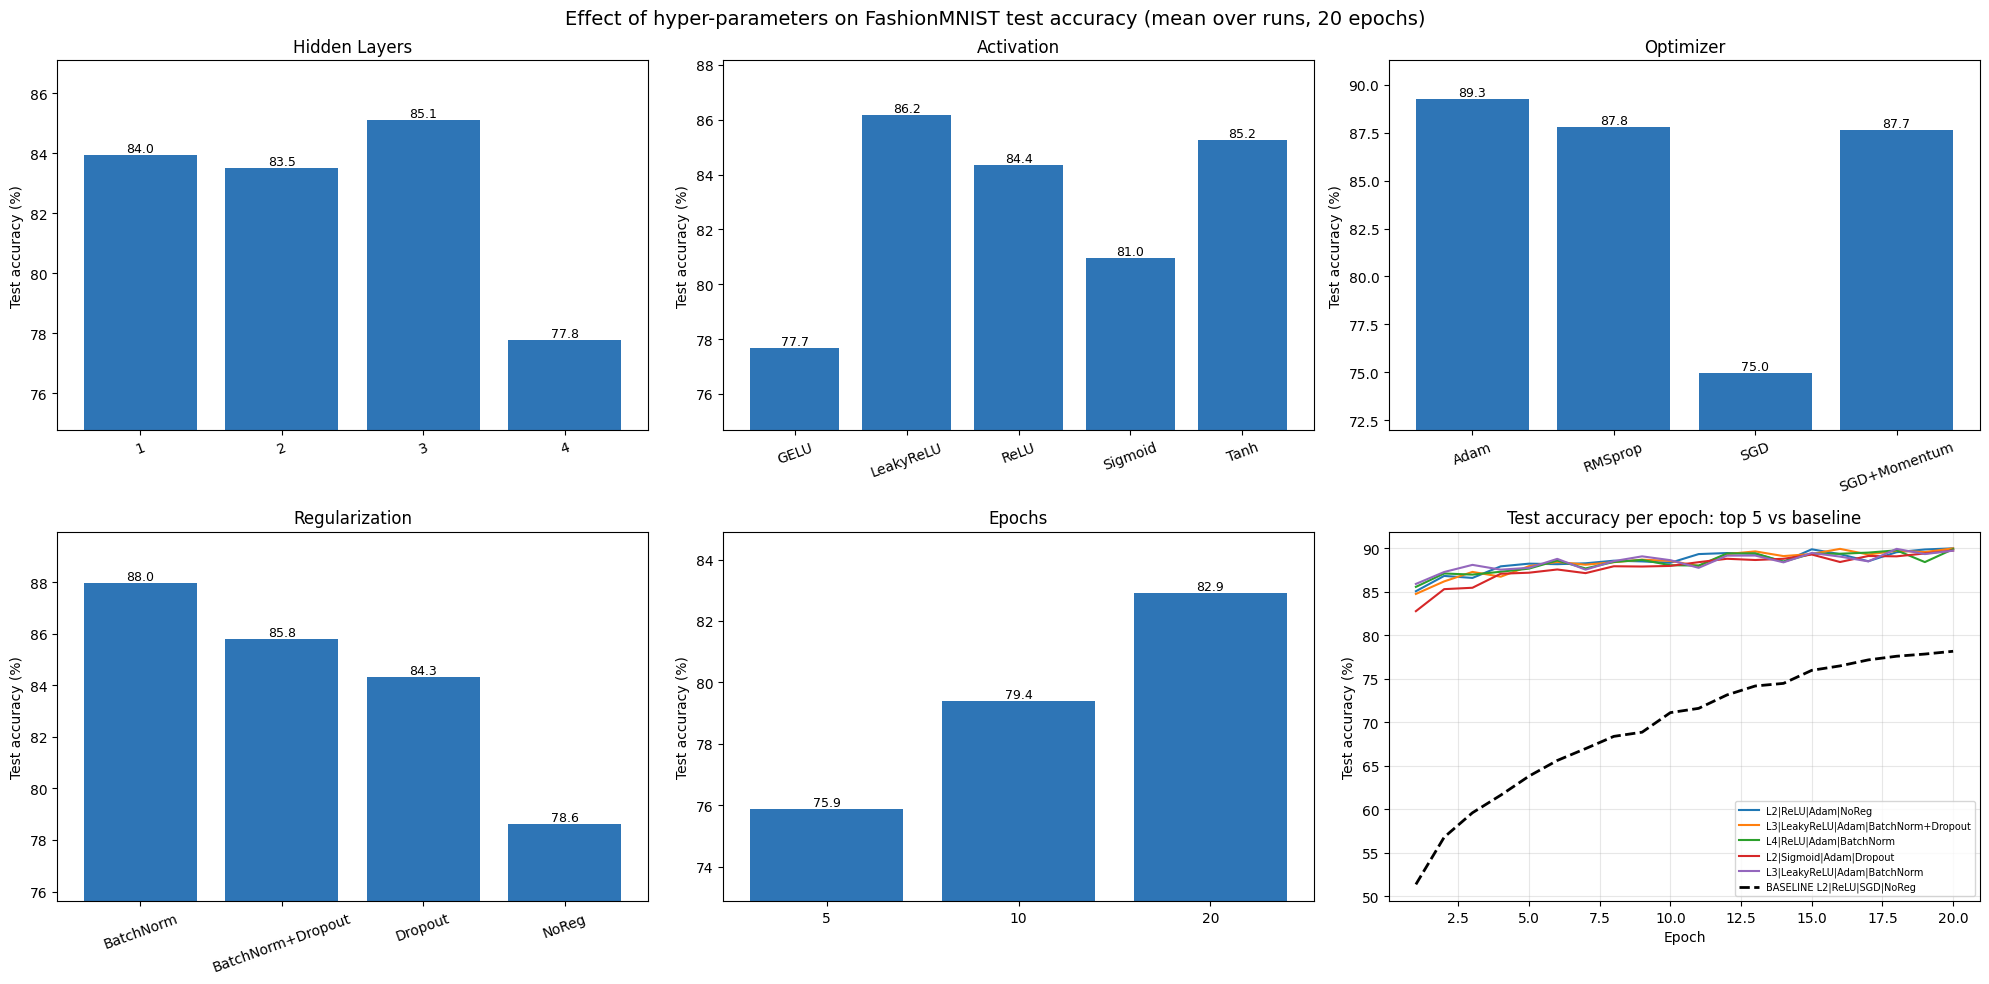

In [22]:
# ---- Quick visual summary (also saved to Drive as a PNG) ----
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
fig.suptitle(f"Effect of hyper-parameters on FashionMNIST test accuracy (mean over runs, {MAX_EPOCHS} epochs)", fontsize=14)

for ax, (col, lab) in zip(axes.flat, FACTORS):
    sub = avg_df[avg_df["Hyperparameter"] == lab]
    vals = sub[f"Mean Test Acc % @ {MAX_EPOCHS} ep"]
    bars = ax.bar(sub["Value"].astype(str), vals, color="#2E75B6")
    ax.set_title(lab); ax.set_ylabel("Test accuracy (%)")
    ax.set_ylim(max(0, vals.min() - 3), min(100, vals.max() + 2))
    ax.bar_label(bars, fmt="%.1f", fontsize=9)
    ax.tick_params(axis="x", rotation=20)

# epochs panel
ax = axes.flat[4]
means = [summary[f"Test Acc % @ {e} ep"].mean() for e in EPOCH_CHECKPOINTS]
bars = ax.bar([str(e) for e in EPOCH_CHECKPOINTS], means, color="#2E75B6")
ax.set_title("Epochs"); ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(max(0, min(means) - 3), min(100, max(means) + 2)); ax.bar_label(bars, fmt="%.1f", fontsize=9)

# learning curves: top 5 + baseline
ax = axes.flat[5]
top_ids = [f"L{r['Hidden Layers']}|{r['Activation']}|{r['Optimizer']}|{r['Regularization']}"
           for _, r in summary.head(5).iterrows()]
for cid in top_ids:
    g = hist[hist["config_id"] == cid]; ax.plot(g["epoch"], g["test_acc"], label=cid)
g = hist[hist["config_id"] == base_id]
ax.plot(g["epoch"], g["test_acc"], "k--", linewidth=2, label=f"BASELINE {base_id}")
ax.set_title("Test accuracy per epoch: top 5 vs baseline"); ax.set_xlabel("Epoch"); ax.set_ylabel("Test accuracy (%)")
ax.legend(fontsize=7); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "hyperparameter_effects.png"), dpi=150)
plt.show()